Data Analysis Python Project- GoPuff Analysis

Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
pip install seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
df=pd.read_csv("goPuff_data.csv")

In [5]:
df

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,low fat,NCT53,Health and Hygiene,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,164.5526,4.0
8519,low fat,FDN09,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.034706,NaN,241.6828,4.0
8520,low fat,DRE13,Soft Drinks,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.027571,NaN,86.6198,4.0
8521,reg,FDT50,Dairy,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.107715,NaN,97.8752,4.0


Sample Data

In [6]:
df.head(10)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0
5,low fat,FDS52,Frozen Foods,2020,OUT017,Tier 2,Small,Supermarket Type1,0.005505,8.89,102.4016,5.0
6,Low Fat,NCU05,Health and Hygiene,2011,OUT010,Tier 3,Small,Grocery Store,0.098312,11.80,81.4618,5.0
7,Low Fat,NCD30,Household,2015,OUT045,Tier 2,Small,Supermarket Type1,0.026904,19.70,96.0726,5.0
8,Low Fat,FDW20,Fruits and Vegetables,2000,OUT013,Tier 3,High,Supermarket Type1,0.024129,20.75,124.1730,5.0
9,Low Fat,FDX25,Canned,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.101562,NaN,181.9292,5.0


In [7]:
df.tail(5)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
8518,low fat,NCT53,Health and Hygiene,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,164.5526,4.0
8519,low fat,FDN09,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.034706,NaN,241.6828,4.0
8520,low fat,DRE13,Soft Drinks,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.027571,NaN,86.6198,4.0
8521,reg,FDT50,Dairy,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.107715,NaN,97.8752,4.0
8522,reg,FDM58,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,112.2544,4.0


Size Of Data

In [8]:
print("Size of Data:" ,df.shape)

Size of Data: (8523, 12)


Field Information


In [9]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='str')

Data Types

In [10]:

df.dtypes

Item Fat Content                 str
Item Identifier                  str
Item Type                        str
Outlet Establishment Year      int64
Outlet Identifier                str
Outlet Location Type             str
Outlet Size                      str
Outlet Type                      str
Item Visibility              float64
Item Weight                  float64
Sales                        float64
Rating                       float64
dtype: object

Data Cleaning

In [11]:
print(df['Item Fat Content'].unique())

<StringArray>
['Regular', 'Low Fat', 'low fat', 'LF', 'reg']
Length: 5, dtype: str


In [12]:
df['Item Fat Content'] =df ['Item Fat Content'].replace({'LF': 'Low Fat', 
                                                         'low fat': 'Low Fat',
                                                         'reg': 'Regular'
                                                        })

In [13]:
print(df['Item Fat Content'].unique())

<StringArray>
['Regular', 'Low Fat']
Length: 2, dtype: str


Business Requirements

KPI's Requirements

In [14]:
# Total Sales
total_sales = df['Sales'].sum()

# Average Sales
avg_sales = df['Sales'].mean()

# Number of Items Sold (no Quantity column, so fallback = count of rows)
no_of_items_sold = df['Sales'].count()

# Average Rating (column name is 'Rating', not 'Ratings')
avg_ratings = df['Rating'].mean()

# Display
print(f"Total sales: ${total_sales:,.0f}")
print(f"Average sales: ${avg_sales:,.0f}")
print(f"Number of items sold: {no_of_items_sold:,.0f}")
print(f"Average rating: {avg_ratings:.2f}")

Total sales: $1,201,681
Average sales: $141
Number of items sold: 8,523
Average rating: 3.97


Chart Contents

Total Sales by Fat Content

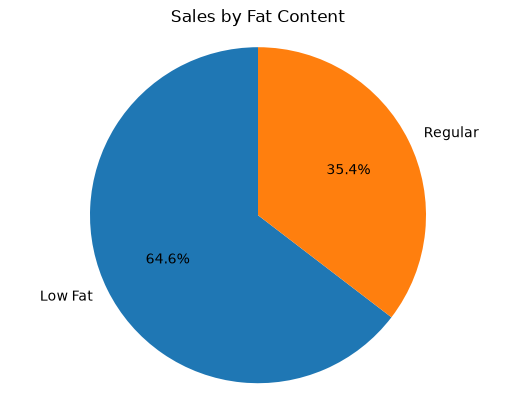

In [15]:
import matplotlib.pyplot as plt

sales_by_fat = df.groupby('Item Fat Content')['Sales'].sum()

plt.pie(
    sales_by_fat,
    labels=sales_by_fat.index,
    autopct='%.1f%%',
    startangle=90
)
plt.title('Sales by Fat Content')
plt.axis('equal')  # Ensures pie chart is a circle
plt.show()

Total Sales by Item Type

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Group and sort sales by item type
sales_by_type = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)


In [17]:
sales_by_type

Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9204
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4596
Canned                    90706.7270
Baking Goods              81894.7364
Health and Hygiene        68025.8388
Meat                      59449.8638
Soft Drinks               58514.1650
Breads                    35379.1198
Hard Drinks               29334.6766
Others                    22451.8916
Starchy Foods             21880.0274
Breakfast                 15596.6966
Seafood                    9077.8700
Name: Sales, dtype: float64

In [18]:
# Set figure size
plt.figure(figsize=(10, 6))


<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

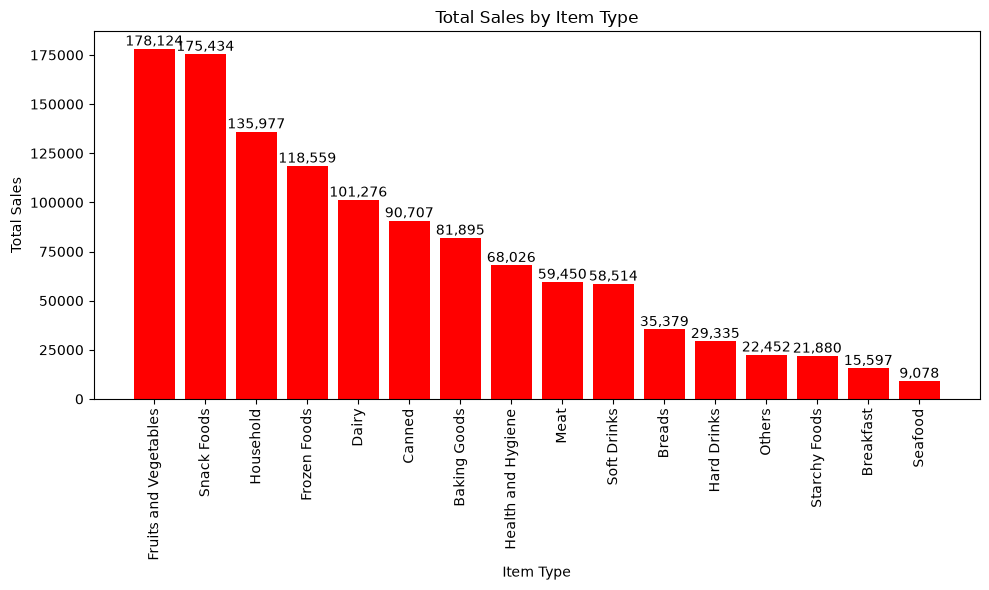

In [19]:
# Set figure size
plt.figure(figsize=(10, 6))

# Create bar chart
bars = plt.bar(sales_by_type.index, sales_by_type.values, color='red')

# Rotate x-axis labels for readability
plt.xticks(rotation=90)
plt.xlabel('Item Type')
plt.ylabel('Total Sales')
plt.title('Total Sales by Item Type')
# Add value labels on top of each bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():,.0f}',
        ha='center',
        va='bottom',
        fontsize=10
    )

# Adjust layout to prevent clipping
plt.tight_layout()
plt.show()


Fat Content by Outlet for Total Sales

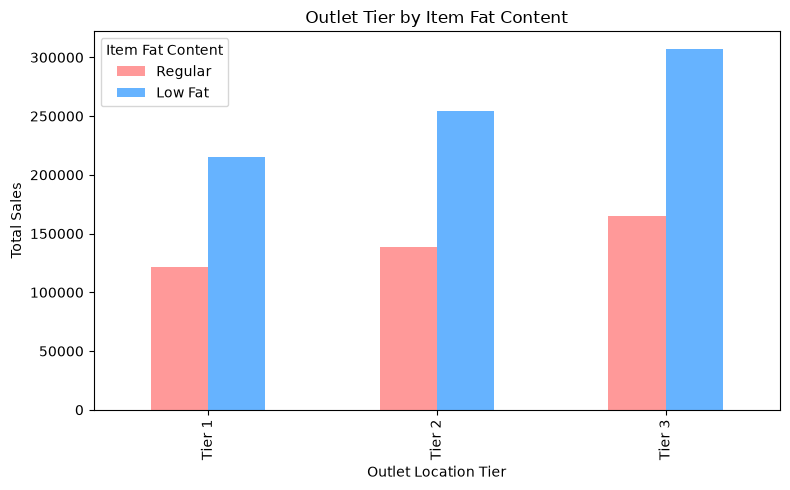

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# Group and reshape the data
grouped = df.groupby(['Outlet Location Type', 'Item Fat Content'])['Sales'].sum().unstack()

# Filter only 'Regular' and 'Low Fat' categories
grouped = grouped[['Regular', 'Low Fat']]

# Plot the grouped bar chart
ax = grouped.plot(
    kind='bar',
    figsize=(8, 5),
    title='Outlet Tier by Item Fat Content',
    color=['#FF9999', '#66B3FF']  # Optional: custom colors
)

# Axis labels and legend
plt.xlabel('Outlet Location Tier')
plt.ylabel('Total Sales')
plt.legend(title='Item Fat Content')
plt.savefig('Outlet_Location_Tier.png')
# Layout adjustment
plt.tight_layout()
plt.show()


Total Sales By Outlet Establishmant

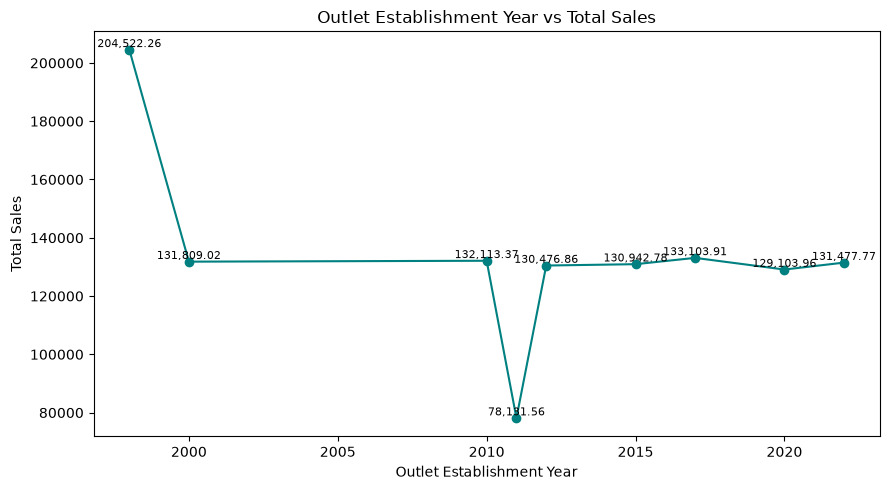

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Line chart: Total Sales by Outlet Establishment Year
sales_by_year = df.groupby('Outlet Establishment Year')['Sales'].sum().sort_index()

plt.figure(figsize=(9, 5))
plt.plot(sales_by_year.index, sales_by_year.values, marker='o', linestyle='-', color='teal')
plt.xlabel('Outlet Establishment Year')
plt.ylabel('Total Sales')
plt.title('Outlet Establishment Year vs Total Sales')

# Add value labels
for x, y in zip(sales_by_year.index, sales_by_year.values):
    plt.text(x, y, f'{y:,.2f}', ha='center', va='bottom', fontsize=8)
plt.savefig('Establish.png')

plt.tight_layout()
plt.show()

Sales by Outlet Size

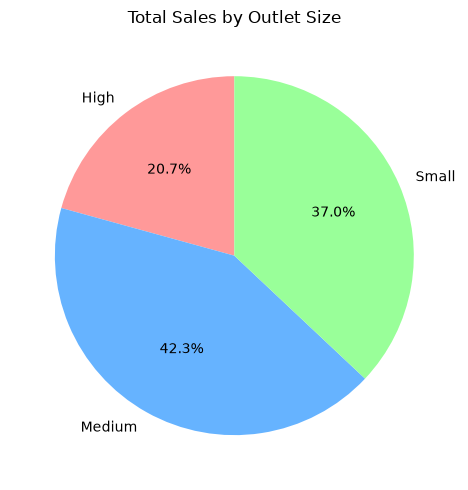

In [22]:
# Pie chart: Total Sales by Outlet Size
sales_by_size = df.groupby('Outlet Size')['Sales'].sum()

plt.figure(figsize=(5, 5))
plt.pie(
    sales_by_size,
    labels=sales_by_size.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#FF9999', '#66B3FF', '#99FF99']  # Optional: custom colors
)
plt.title('Total Sales by Outlet Size')
plt.savefig('Total Sales by Outlet Size.png')
plt.tight_layout()
plt.show()

Sales by Outlet Location

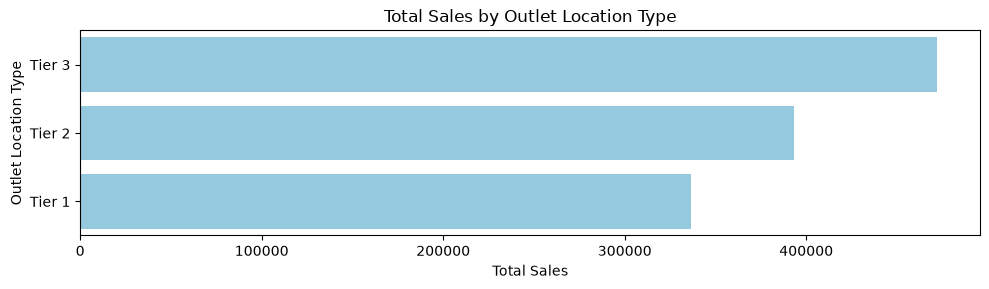

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Group and sort sales by outlet location type
sales_by_location = (
    df.groupby('Outlet Location Type')['Sales']
      .sum()
      .reset_index()
      .sort_values('Sales', ascending=False)
)

# Set figure size
plt.figure(figsize=(10, 3))  # Wide layout, compact height

# Create horizontal bar chart (using color instead of palette to avoid warning)
ax = sns.barplot(
    x='Sales',
    y='Outlet Location Type',
    data=sales_by_location,
    color='skyblue'  # Single color for all bars
)

# Add titles and labels
plt.title('Total Sales by Outlet Location Type')
plt.xlabel('Total Sales')
plt.ylabel('Outlet Location Type')

# Adjust layout to prevent clipping
plt.savefig('Total Sales by Outlet Location Type.png')
plt.tight_layout()
plt.show()

In [24]:
df.shape

(8523, 12)

In [25]:
df.dtypes

Item Fat Content                 str
Item Identifier                  str
Item Type                        str
Outlet Establishment Year      int64
Outlet Identifier                str
Outlet Location Type             str
Outlet Size                      str
Outlet Type                      str
Item Visibility              float64
Item Weight                  float64
Sales                        float64
Rating                       float64
dtype: object

In [26]:
df.info

<bound method DataFrame.info of      Item Fat Content Item Identifier              Item Type  \
0             Regular           FDX32  Fruits and Vegetables   
1             Low Fat           NCB42     Health and Hygiene   
2             Regular           FDR28           Frozen Foods   
3             Regular           FDL50                 Canned   
4             Low Fat           DRI25            Soft Drinks   
...               ...             ...                    ...   
8518          Low Fat           NCT53     Health and Hygiene   
8519          Low Fat           FDN09            Snack Foods   
8520          Low Fat           DRE13            Soft Drinks   
8521          Regular           FDT50                  Dairy   
8522          Regular           FDM58            Snack Foods   

      Outlet Establishment Year Outlet Identifier Outlet Location Type  \
0                          2012            OUT049               Tier 1   
1                          2022            OUT018  

In [27]:
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,8523.000000,8523.000000,7060.000000,8523.000000,8523.000000
mean,2010.831867,0.066132,12.857645,140.992782,3.965857
std,8.371760,0.051598,4.643456,62.275067,0.605651
min,1998.000000,0.000000,4.555000,31.290000,1.000000
25%,2000.000000,0.026989,8.773750,93.826500,4.000000
50%,2012.000000,0.053931,12.600000,143.012800,4.000000
75%,2017.000000,0.094585,16.850000,185.643700,4.200000
max,2022.000000,0.328391,21.350000,266.888400,5.000000


In [28]:
df.isnull().sum()

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64

In [29]:
df['Item Weight'] = df['Item Weight'].fillna(df['Item Weight'].mean())

In [30]:
df.isnull().sum()

Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Item Weight                  0
Sales                        0
Rating                       0
dtype: int64

In [31]:
df.tail(25)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
8498,Regular,FDG46,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.032750,12.857645,112.1518,4.0
8499,Regular,FDJ21,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.038342,12.857645,146.2102,4.0
8500,Regular,FDK58,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.044765,12.857645,102.4016,4.0
8501,Regular,FDN34,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.045543,12.857645,170.7132,4.0
8502,Regular,FDP21,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.025616,12.857645,188.1872,4.0
8503,Regular,FDR22,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.018473,12.857645,109.9544,4.0
8504,Regular,FDS09,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.080696,12.857645,51.3008,4.0
8505,Regular,FDS34,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.076387,12.857645,112.1518,4.0
8506,Regular,FDU09,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.066275,12.857645,54.1956,4.0
8507,Regular,FDU33,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.134057,12.857645,45.3402,4.0


In [32]:
!pip install sqlalchemy pyodbc pandas
import pandas as pd
from sqlalchemy import create_engine
server = 'your_server_name'  # e.g., 'DESKTOP-AIFF1C6\SQLEXPRESS'
database = 'GopuffDB'
username = 'your_username'
password = 'your_password'

connection_string = f'mssql+pyodbc://{username}:{password}@{server}/{database}?driver=ODBC+Driver+17+for+SQL+Server'
engine = create_engine(connection_string)
df = pd.read_sql_query('SELECT * FROM YourTableName', engine)


[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


InterfaceError: (pyodbc.InterfaceError) ('IM002', '[IM002] [Microsoft][ODBC Driver Manager] Data source name not found and no default driver specified (0) (SQLDriverConnect)')
(Background on this error at: https://sqlalche.me/e/20/rvf5)

In [ ]:
!pip install sqlalchemy pyodbc pandas


[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
from sqlalchemy import create_engine

In [ ]:
server = r'DESKTOP-AIFF1C6\SQLEXPRESS'  # Use raw string or double backslash
database = 'GopuffDB'

connection_string = f'mssql+pyodbc://@{server}/{database}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes'

In [ ]:
import pandas as pd
from sqlalchemy import create_engine

server = r'DESKTOP-AIFF1C6\SQLEXPRESS'  # Use raw string or double backslash
database = 'GopuffDB'

connection_string = f'mssql+pyodbc://@{server}/{database}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes'

engine = create_engine(connection_string)

df = pd.read_sql_query('SELECT * FROM gopuff_data', engine)

print(df.head())

InterfaceError: (pyodbc.InterfaceError) ('IM002', '[IM002] [Microsoft][ODBC Driver Manager] Data source name not found and no default driver specified (0) (SQLDriverConnect)')
(Background on this error at: https://sqlalche.me/e/20/rvf5)

In [ ]:
df.rename(columns={'Item_Fat_Content': 'Item_Fat_Content1'}, inplace=True)

In [ ]:
print(df.head(15))

   Item Fat Content Item Identifier              Item Type  \
0           Regular           FDX32  Fruits and Vegetables   
1           Low Fat           NCB42     Health and Hygiene   
2           Regular           FDR28           Frozen Foods   
3           Regular           FDL50                 Canned   
4           Low Fat           DRI25            Soft Drinks   
5           Low Fat           FDS52           Frozen Foods   
6           Low Fat           NCU05     Health and Hygiene   
7           Low Fat           NCD30              Household   
8           Low Fat           FDW20  Fruits and Vegetables   
9           Low Fat           FDX25                 Canned   
10          Low Fat           FDX21            Snack Foods   
11          Low Fat           NCU41     Health and Hygiene   
12          Low Fat           FDL20  Fruits and Vegetables   
13          Low Fat           NCR54              Household   
14          Low Fat           FDH19                   Meat   

    Out

In [ ]:
df_transposed = df.T
print(df_transposed)

                                            0                   1     \
Item Fat Content                         Regular             Low Fat   
Item Identifier                            FDX32               NCB42   
Item Type                  Fruits and Vegetables  Health and Hygiene   
Outlet Establishment Year                   2012                2022   
Outlet Identifier                         OUT049              OUT018   
Outlet Location Type                      Tier 1              Tier 3   
Outlet Size                               Medium              Medium   
Outlet Type                    Supermarket Type1   Supermarket Type2   
Item Visibility                         0.100014            0.008596   
Item Weight                                 15.1                11.8   
Sales                                   145.4786            115.3492   
Rating                                       5.0                 5.0   

                                        2                  3   

In [ ]:
single_row = df.iloc[0]  # first row as a Series
print(single_row)

Item Fat Content                           Regular
Item Identifier                              FDX32
Item Type                    Fruits and Vegetables
Outlet Establishment Year                     2012
Outlet Identifier                           OUT049
Outlet Location Type                        Tier 1
Outlet Size                                 Medium
Outlet Type                      Supermarket Type1
Item Visibility                           0.100014
Item Weight                                   15.1
Sales                                     145.4786
Rating                                         5.0
Name: 0, dtype: object


In [ ]:
import pandas as pd
single_row_df = pd.DataFrame([df.columns.tolist(), df.iloc[0].tolist()])
print(single_row_df)

                 0                1                      2   \
0  Item Fat Content  Item Identifier              Item Type   
1           Regular            FDX32  Fruits and Vegetables   

                          3                  4                     5   \
0  Outlet Establishment Year  Outlet Identifier  Outlet Location Type   
1                       2012             OUT049                Tier 1   

            6                  7                8            9         10  \
0  Outlet Size        Outlet Type  Item Visibility  Item Weight     Sales   
1       Medium  Supermarket Type1         0.100014         15.1  145.4786   

       11  
0  Rating  
1     5.0  


In [ ]:
single_row_str = ', '.join(df.iloc[0].astype(str))
print(single_row_str)

Regular, FDX32, Fruits and Vegetables, 2012, OUT049, Tier 1, Medium, Supermarket Type1, 0.1000135, 15.1, 145.4786, 5.0


In [ ]:
# Create the string from the first row
single_row_str = ', '.join(df.iloc[0].astype(str))

# Print or use the string later
print(single_row_str)

# You can also save it to a text file
with open('single_row.txt', 'w') as f:
    f.write(single_row_str)

Regular, FDX32, Fruits and Vegetables, 2012, OUT049, Tier 1, Medium, Supermarket Type1, 0.1000135, 15.1, 145.4786, 5.0


In [ ]:
import json
 
# JSON Data
data = {
	"name": "Aman",
	"age": 25,
	"department": "Analytics",
	"skills": ["Python", "SQL", "Tableau"]
}
 
# Writing JSON to file
with open("data.json", "w") as json_file:
	json.dump(data, json_file)
 
# Reading JSON from file
with open("data.json", "r") as json_file:
	loaded_data = json.load(json_file)
	print(loaded_data)
	print("Employee Name:", loaded_data["name"])

{'name': 'Aman', 'age': 25, 'department': 'Analytics', 'skills': ['Python', 'SQL', 'Tableau']}
Employee Name: Aman
